In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the house price dataset

df = pd.read_csv("../data/housing.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (20640, 9)


In [3]:
# Display the first 5 rows of the dataset

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
# Check for missing values

df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [6]:
# Display statistical summary of the dataset

df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


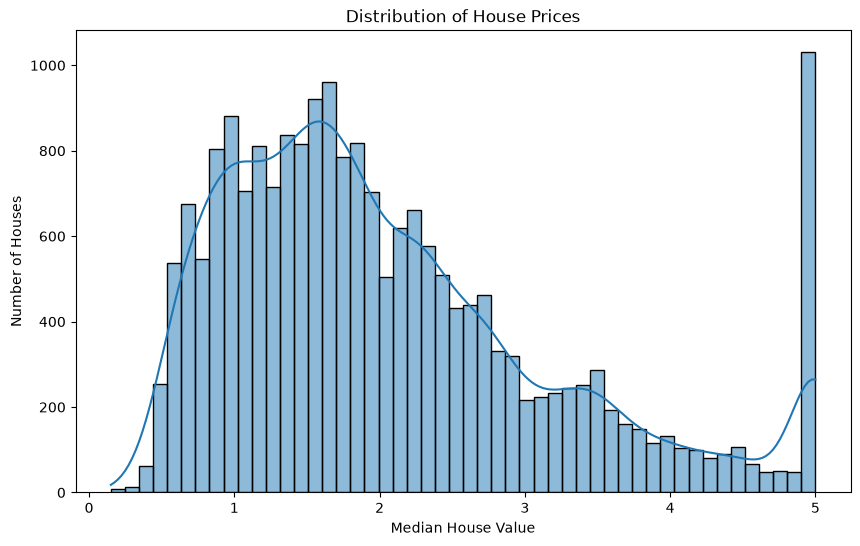

In [7]:
# Distribution of house prices

plt.figure(figsize=(10, 6))
sns.histplot(df["MedHouseVal"], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")

plt.show()

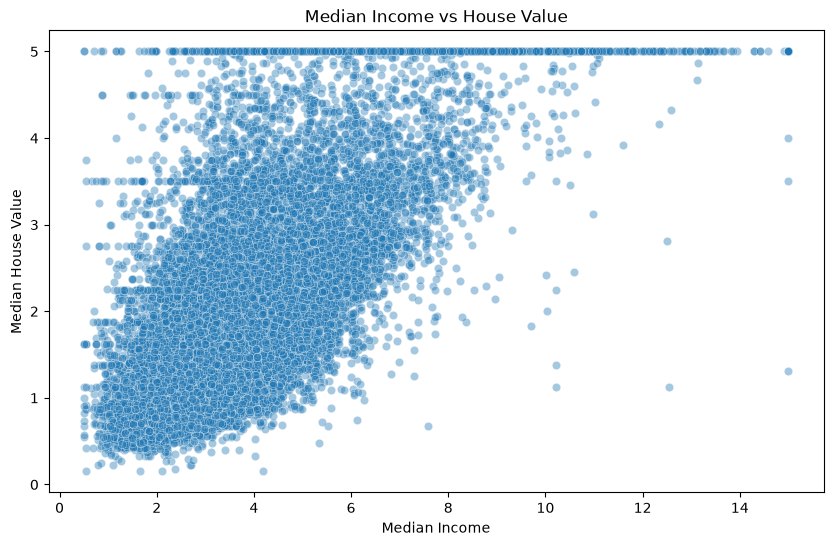

In [8]:
# Relationship between median income and house value

plt.figure(figsize=(10, 6))
sns.scatterplot(x="MedInc", y="MedHouseVal", data=df, alpha=0.4)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

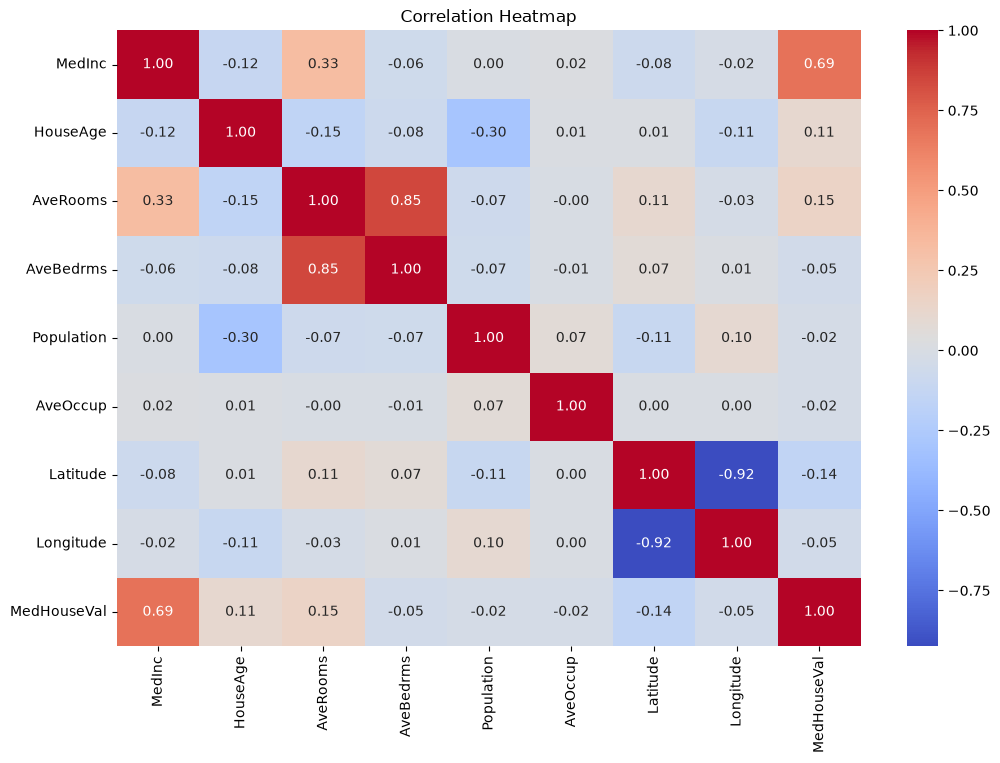

In [9]:
# Create a correlation heatmap

plt.figure(figsize=(12, 8))

correlation_matrix = df.corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

In [10]:
# Separate features and target variable

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (20640, 8)
Target (y) shape: (20640,)


In [11]:
# Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [12]:
# Train a Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [13]:
# Make predictions using the trained model

y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("First 5 predicted house values:")
print(y_pred[:5])

Predictions generated successfully!
First 5 predicted house values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [14]:
# Evaluate the Linear Regression model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("R² Score:", r2)

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 0.533200130495656
Mean Squared Error (MSE): 0.5558915986952437
R² Score: 0.5757877060324512


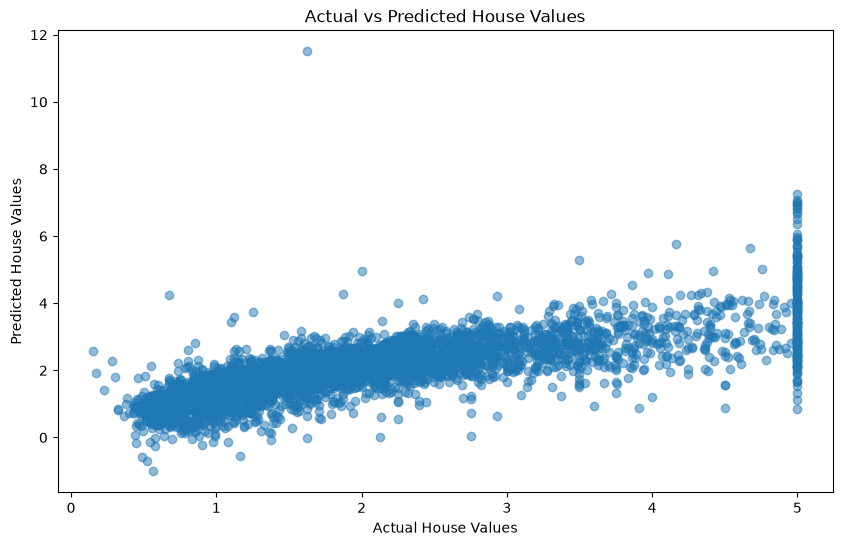

In [15]:
# Compare actual and predicted house values

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.show()

In [16]:
# Train a Random Forest Regression model

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [17]:
# Make predictions using the Random Forest model

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("First 5 predicted house values:")
print(rf_pred[:5])

Random Forest predictions generated successfully!
First 5 predicted house values:
[0.50809   0.75064   4.9582073 2.50172   2.24778  ]


In [18]:
# Evaluate the Random Forest model

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("Mean Absolute Error (MAE):", rf_mae)
print("Mean Squared Error (MSE):", rf_mse)
print("R² Score:", rf_r2)

Random Forest Evaluation Results
--------------------------------
Mean Absolute Error (MAE): 0.32773108008720947
Mean Squared Error (MSE): 0.25602182673365537
R² Score: 0.8046244867176197


In [19]:
# Compare the performance of both models

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "R2 Score": [r2, rf_r2]
})

results

,Model,MAE,MSE,R2 Score
0,Linear Regression,0.533200,0.555892,0.575788
1,Random Forest,0.327731,0.256022,0.804624


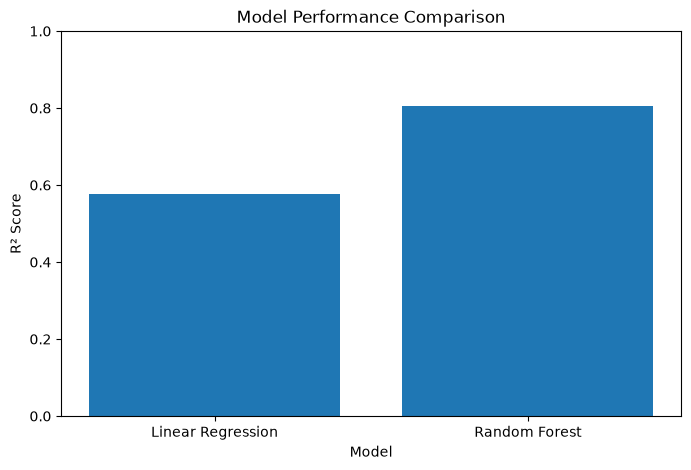

In [20]:
# Visualize R² score comparison

plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["R2 Score"])

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)

plt.show()

In [21]:
# Check feature importance from the Random Forest model

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,MedInc,0.524980
5,AveOccup,0.138367
6,Latitude,0.089035
7,Longitude,0.088474
1,HouseAge,0.054602
2,AveRooms,0.044216
4,Population,0.030662
3,AveBedrms,0.029663


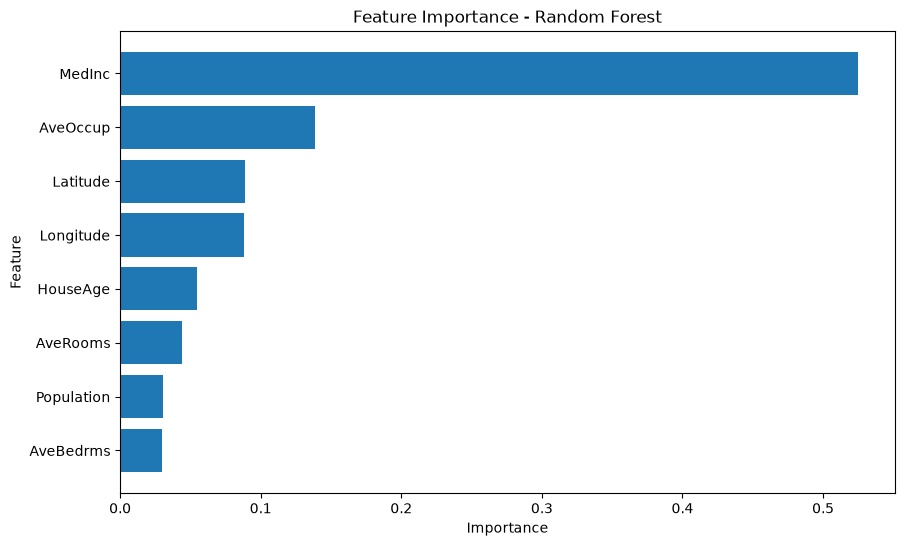

In [22]:
# Visualize feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.show()

In [23]:
# Create a function to predict the price of a new house

def predict_house_price(
    MedInc,
    HouseAge,
    AveRooms,
    AveBedrms,
    Population,
    AveOccup,
    Latitude,
    Longitude
):
    house_data = pd.DataFrame([[
        MedInc,
        HouseAge,
        AveRooms,
        AveBedrms,
        Population,
        AveOccup,
        Latitude,
        Longitude
    ]], columns=X.columns)

    prediction = rf_model.predict(house_data)

    return prediction[0]


print("Prediction function created successfully!")

Prediction function created successfully!


In [24]:
# Test the prediction function with a new house

predicted_price = predict_house_price(
    MedInc=5.0,
    HouseAge=20.0,
    AveRooms=6.0,
    AveBedrms=1.0,
    Population=1000.0,
    AveOccup=3.0,
    Latitude=34.05,
    Longitude=-118.25
)

print("Predicted House Value:", predicted_price)

Predicted House Value: 2.3654199999999994


In [25]:
# Save the trained Random Forest model

import joblib

joblib.dump(rf_model, "../src/house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
